<a href="https://colab.research.google.com/github/vaibhavi27122006/DAV_LAB/blob/main/program11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

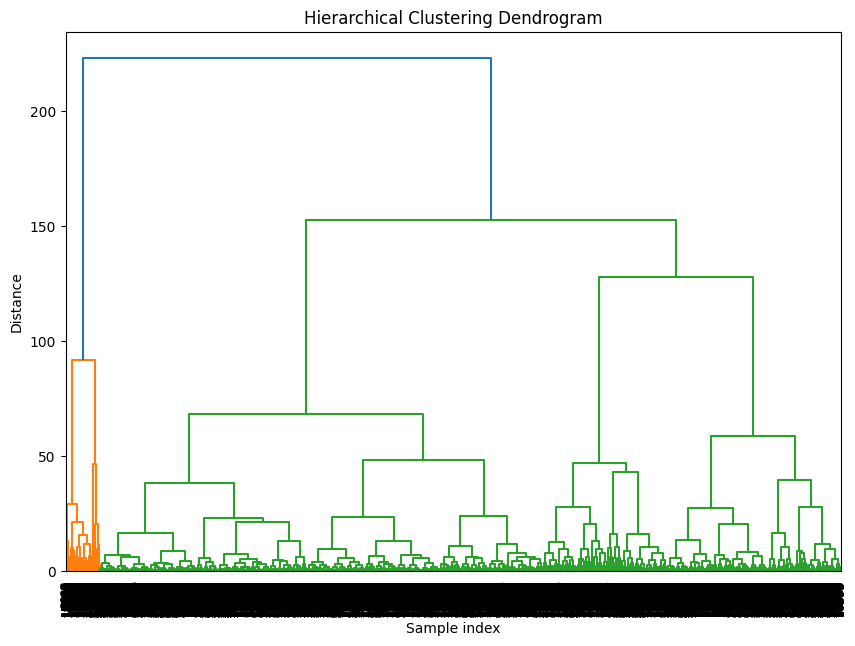

Clustering completed. Here are the first few rows with cluster labels:


,price,bedrooms,baths,Area Size,cluster_labels
0,66900.0,5612.0,1283.0,472.0,0
1,80100.0,7650.0,1901.0,463.0,0
2,85700.0,720.0,174.0,117.0,2
3,73400.0,1501.0,337.0,226.0,2
4,65500.0,1454.0,326.0,262.0,2


In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Ensure df exists before continuing
if 'df' in locals() or 'df' in globals():
    # Standardize the features
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(df)

    # Generate the linkage matrix using Ward's method
    Z = linkage(scaled_features, method='ward')

    # Plot the Dendrogram
    plt.figure(figsize=(10, 7))
    plt.title("Hierarchical Clustering Dendrogram")
    plt.xlabel("Sample index")
    plt.ylabel("Distance")
    dendrogram(
        Z,
        leaf_rotation=90.,
        leaf_font_size=8.,
    )
    plt.show()

    # Fit Agglomerative Clustering (using metric instead of affinity to avoid deprecation warnings)
    cluster = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
    df['cluster_labels'] = cluster.fit_predict(scaled_features)

    print("Clustering completed. Here are the first few rows with cluster labels:")
    display(df.head())
else:
    print("Error: 'df' is not defined. Please run cell xQP3xw5pEW32 first to load the data!")

In [ ]:
import os
import pandas as pd

file_path = '/content/House_Price_dataset.csv'

if os.path.exists(file_path):
    print("Loading your uploaded House Price dataset...")
    df = pd.read_csv(file_path)
    df = df[df['purpose'] == 'For Sale']
    df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()
else:
    fallback_path = '/content/sample_data/california_housing_train.csv'
    print(f"'{file_path}' not found. Loading fallback Colab dataset: '{fallback_path}'...")
    df = pd.read_csv(fallback_path)
    # Select numerical columns for fallback clustering demonstration
    df = df[['median_house_value', 'total_rooms', 'total_bedrooms', 'households']].dropna()
    # Rename columns to align with the rest of your clustering workflow
    df.columns = ['price', 'bedrooms', 'baths', 'Area Size']

print("Data loaded successfully. Shape:", df.shape)

'/content/House_Price_dataset.csv' not found. Loading fallback Colab dataset: '/content/sample_data/california_housing_train.csv'...
Data loaded successfully. Shape: (17000, 4)


/tmp/ipykernel_4319/883980956.py:8: DtypeWarning: Columns (0,1,4,8,9,10,13,18) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/House_Price_dataset (1).csv', on_bad_lines='skip')


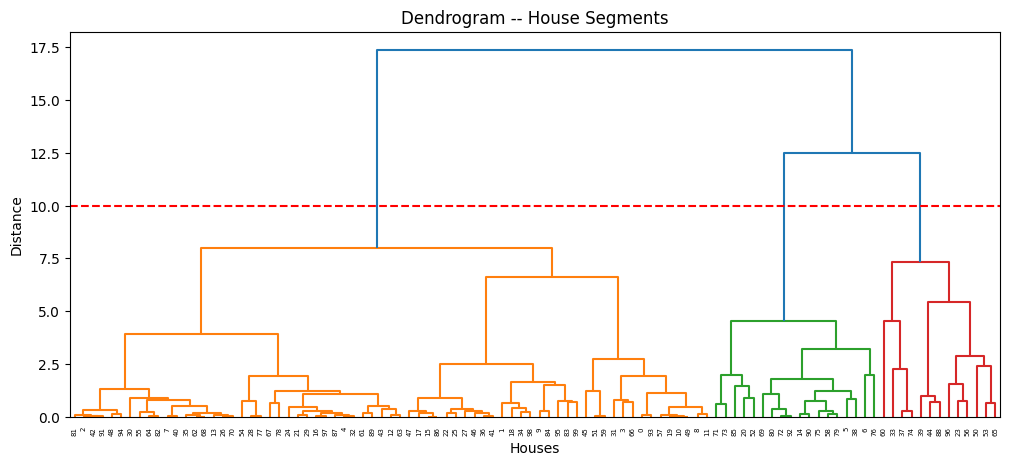

HC_Cluster
0    69
2    18
1    13
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           11404202.90      3.00   3.10       5.89
1           62130769.23      6.00   5.85       1.60
2           24555555.56      5.28   5.72      10.33


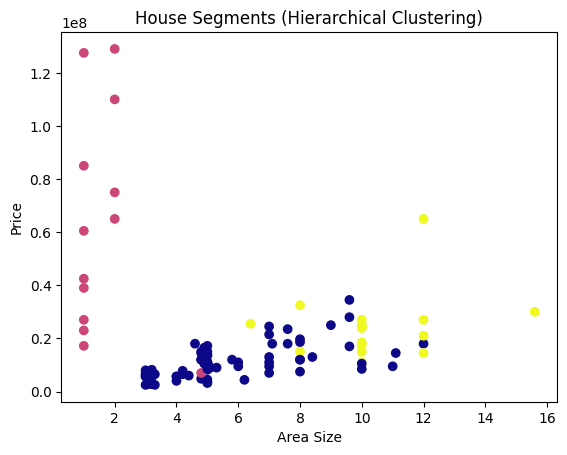

In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Load and filter dataset (handling bad lines with on_bad_lines='skip')





df = pd.read_csv('/content/House_Price_dataset (1).csv', on_bad_lines='skip')
df = df[df['purpose'] == 'For Sale']

# Keep only required columns
target_cols = ['price', 'bedrooms', 'baths', 'Area Size']
df = df[target_cols]

# Safely convert columns to numeric, forcing errors to NaN
for col in target_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop any rows that became NaN during conversion
df = df.dropna()

# Remove invalid values and extreme outliers
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

# Sample 100 rows for clustering
df = df.sample(n=100, random_state=42).reset_index(drop=True)

# Scale features
X = df[['price', 'bedrooms', 'baths', 'Area Size']]
X_scaled = StandardScaler().fit_transform(X)

# Plot Dendrogram
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(linked)
plt.title('Dendrogram -- House Segments')
plt.xlabel('Houses')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

# Fit Agglomerative Clustering
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['HC_Cluster'] = hc.fit_predict(X_scaled)

# Print cluster distribution and mean values
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

# Scatter plot of the clusters
plt.scatter(df['Area Size'], df['price'], c=df['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierarchical Clustering)')
plt.show()